In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import re
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from wordcloud import WordCloud
from collections import Counter
import random
import nltk
from nltk.corpus import stopwords

In [3]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /Users/maryc/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [4]:
df_ba = pd.read_csv('BusinessAnalyst.csv')
df_da = pd.read_csv('DataAnalyst.csv')
df_de = pd.read_csv('DataEngineer.csv')
df_ds = pd.read_csv('DataScientist.csv')

In [5]:
cols = [
    'Job Title', 'Salary Estimate', 'Job Description', 'Rating',
    'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
    'Type of ownership', 'Industry', 'Sector', 'Revenue',
    'Competitors', 'Easy Apply'
]

In [6]:
df_ba = df_ba[cols]
df_da = df_da[cols]
df_de = df_de[cols]
df_ds = df_ds[cols]

In [7]:
df_ba['role'] = 'BA'
df_da['role'] = 'DA'
df_de['role'] = 'DE'
df_ds['role'] = 'DS'

In [8]:
df = pd.concat([df_ba, df_da, df_de, df_ds], ignore_index=True)

##очистка

In [9]:
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

Упрощаем job_title

In [10]:
df['job_title'] = df['job_title'].str.split(',').str[0]
df['job_title'] = df['job_title'].str.split('/').str[0]
df['job_title'] = df['job_title'].str.split('-').str[0]
df['job_title'] = df['job_title'].str.strip()

Извлекаем среднюю зарплату

In [11]:
def extract_avg_salary(x):
    if pd.isna(x) or x == '-1':
        return np.nan
    nums = re.findall(r'\$?(\d+)K', str(x))
    if len(nums) == 2:
        return (int(nums[0]) + int(nums[1])) / 2
    elif len(nums) == 1:
        return int(nums[0])
    else:
        return np.nan

In [12]:
df['salary_avg_k'] = df['salary_estimate'].apply(extract_avg_salary)

Рейтинг

In [13]:
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df['rating'] = df['rating'].replace(-1.0, np.nan)

Убираем рейтинг из company_name

In [14]:
df['company_name'] = df['company_name'].astype(str)
df['company_name'] = df['company_name'].apply(lambda x: x.split('\n')[0] if '\n' in x else x)
df['company_name'] = df['company_name'].apply(lambda x: re.sub(r'\d\.\d$', '', x).strip())

Location и Headquarters - только город

In [15]:
df['location_city'] = df['location'].str.split(',').str[0].str.strip()
df['hq_city'] = df['headquarters'].str.split(',').str[0].str.strip()

Size в среднее количество сотрудников

In [16]:
def clean_size(x):
    if pd.isna(x) or x in ['-1', 'Unknown']:
        return np.nan
    x = str(x)
    if 'to' in x:
        a, b = x.split('to')
        a = re.findall(r'\d+', a)[0]
        b = re.findall(r'\d+', b)[0]
        return (int(a) + int(b)) / 2
    elif '+' in x:
        return int(re.findall(r'\d+', x)[0]) + 500
    elif 'employees' in x:
        return int(re.findall(r'\d+', x)[0])
    else:
        return np.nan

In [17]:
df['size_avg'] = df['size'].apply(clean_size)

Founded

In [18]:
df['founded'] = pd.to_numeric(df['founded'], errors='coerce')

Ownership

In [19]:
df['ownership'] = df['type_of_ownership'].astype(str)
df['ownership'] = df['ownership'].replace(['-1', 'Unknown'], np.nan)
df['ownership'] = df['ownership'].apply(lambda x: x.replace('Company - ', '') if pd.notna(x) else x)

 доход

In [20]:
def revenue_to_numeric(x):
    if pd.isna(x) or x in ['-1', 'Unknown / Non-Applicable']:
        return np.nan
    x = str(x)
    if 'billion' in x or '+ billion' in x:
        return 10
    elif 'million' in x and ('100 to 500' in x or '500 to 1' in x or '1 to 2' in x or '2 to 5' in x or '5 to 10' in x):
        return 5
    elif 'million' in x:
        return 2
    else:
        return 1

In [21]:
df['revenue_level'] = df['revenue'].apply(revenue_to_numeric)

In [22]:
df['easy_apply'] = df['easy_apply'].replace(['-1', 'False'], False)
df['easy_apply'] = df['easy_apply'].replace(['True', 'TRUE'], True)
df['easy_apply'] = df['easy_apply'].fillna(False).astype(bool)

/var/folders/8_/ss2c3myd785fm4m9w3q294100000gn/T/ipykernel_770/431346128.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['easy_apply'] = df['easy_apply'].fillna(False).astype(bool)


In [23]:
df['easy_apply'] = df['easy_apply'].replace(['-1', 'False'], False)
df['easy_apply'] = df['easy_apply'].replace(['True', 'TRUE'], True)
df['easy_apply'] = df['easy_apply'].fillna(False).astype(bool)

пропуски

In [24]:
df['salary_avg_k'] = df.groupby('job_title')['salary_avg_k'].transform(lambda x: x.fillna(x.median()))
df['salary_avg_k'] = df['salary_avg_k'].fillna(df['salary_avg_k'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  

In [25]:
df['rating'] = df.groupby('sector')['rating'].transform(lambda x: x.fillna(x.median()))
df['rating'] = df['rating'].fillna(df['rating'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  

In [26]:
df['size_avg'] = df.groupby('sector')['size_avg'].transform(lambda x: x.fillna(x.median()))
df['size_avg'] = df['size_avg'].fillna(df['size_avg'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  

In [27]:
df['revenue_level'] = df.groupby('sector')['revenue_level'].transform(lambda x: x.fillna(x.median()))
df['revenue_level'] = df['revenue_level'].fillna(df['revenue_level'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  

In [28]:
df['ownership'] = df['ownership'].fillna('unknown')

In [29]:
df['company_age'] = 2025 - df['founded']
df['company_age'] = df.groupby('sector')['company_age'].transform(lambda x: x.fillna(x.median()))
df['company_age'] = df['company_age'].fillna(df['company_age'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  

##кодирование

In [ ]:
string_cols = ['job_title', 'company_name', 'location_city', 'hq_city', 'ownership', 'sector', 'industry']
for col in string_cols:
    df[col] = df[col].astype(str).str.lower()

Кодируем категории

In [31]:
import pandas as pd
import numpy as np
import re
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder, MultiLabelBinarizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from collections import Counter

In [32]:
for col in ['job_title', 'company_name', 'location_city', 'hq_city', 'ownership', 'sector', 'industry']:
    df[col + '_code'] = LabelEncoder().fit_transform(df[col])

##Преобразуем описание в список ключевых слов

In [33]:
def process_description(text):
    if pd.isna(text) or text == '-1':
        return []
    text = re.sub(r'[^\w\s]', '', str(text).lower())  # Удаляем пунктуацию
    words = text.split()
    words = [word for word in words if word not in stop_words and len(word) > 2]
    return list(set(words))  # Удаляем дубликаты

df['keywords'] = df['job_description'].apply(process_description)

Кодирование keywords с MultiLabelBinarizer

In [34]:
mlb = MultiLabelBinarizer()
X_keywords = mlb.fit_transform(df['keywords'])
X_keywords = pd.DataFrame(X_keywords, columns=mlb.classes_, index=df.index)

In [35]:
numeric_and_coded_cols = [
    'salary_avg_k', 'rating', 'size_avg', 'company_age', 'revenue_level', 'easy_apply',
    'job_title_code', 'company_name_code', 'location_city_code', 'hq_city_code',
    'ownership_code', 'sector_code', 'industry_code'
]

In [36]:
X_numeric_coded = df[numeric_and_coded_cols]

масштабирование

In [37]:
scaler = StandardScaler()
X_numeric_coded_scaled = scaler.fit_transform(X_numeric_coded)
X_numeric_coded_scaled = pd.DataFrame(X_numeric_coded_scaled, columns=numeric_and_coded_cols, index=df.index)

In [38]:
X = pd.concat([X_keywords, X_numeric_coded_scaled], axis=1)

##кластеризация

In [39]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

In [40]:
sil_score = silhouette_score(X, df['cluster'])
print(f"Silhouette Score: {sil_score:.4f}")

Silhouette Score: -0.0097


In [41]:
print("\nРаспределение исходных ролей по кластерам:")
print(pd.crosstab(df['role'], df['cluster']).style.background_gradient(cmap='pink'))


Распределение исходных ролей по кластерам:


In [42]:
from sklearn.decomposition import PCA
import plotly.express as px

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

vis_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'cluster': df['cluster'].astype(str),
    'role': df['role']
})

fig = px.scatter(
    vis_df, x='PC1', y='PC2', color='cluster', symbol='role',
    title='Кластеризация вакансий (4 кластера)',
    labels={'cluster': 'Кластер', 'role': 'Исходная роль'},
    width=1000, height=700
)
fig.show()

In [43]:
agglo = AgglomerativeClustering(n_clusters=4, linkage='ward')
df['agglo_cluster'] = agglo.fit_predict(X)
agglo_sil = silhouette_score(X, df['agglo_cluster'])
print(f"Agglomerative Silhouette Score: {agglo_sil:.4f}")

Agglomerative Silhouette Score: -0.0026


In [45]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.decomposition import TruncatedSVD
from scipy.stats import mstats
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import plotly.express as px
from sklearn.decomposition import PCA

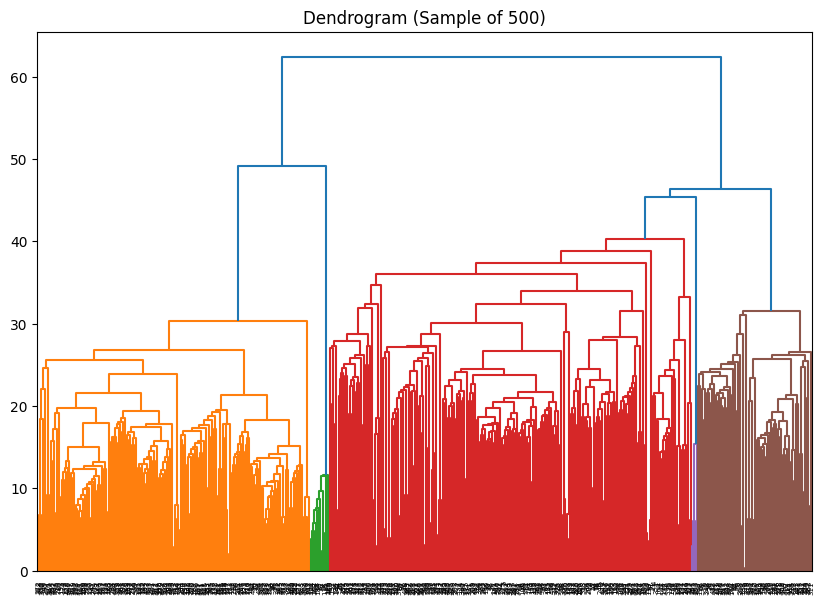

In [46]:
sample_X = X[:500]
linked = linkage(sample_X, 'ward')
plt.figure(figsize=(10, 7))
dendrogram(linked, orientation='top', distance_sort='descending', show_leaf_counts=True)
plt.title('Dendrogram (Sample of 500)')
plt.show()

In [47]:
from sklearn.decomposition import PCA
import plotly.express as px
import matplotlib.pyplot as plt

# Создаем PCA для визуализации (один раз для всех методов)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

In [48]:
vis_df_agglo = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'cluster': df['agglo_cluster'].astype(str),
    'role': df['role']
})

fig_agglo = px.scatter(
    vis_df_agglo, x='PC1', y='PC2', color='cluster', symbol='role',
    title='Agglomerative Clustering (иерархическая кластеризация)',
    labels={'cluster': 'Кластер', 'role': 'Исходная роль'},
    width=1000, height=700
)
fig_agglo.show()